<a href="https://colab.research.google.com/github/ichaxpro/PCVK_2026/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum

## D1. Tugas Individu

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

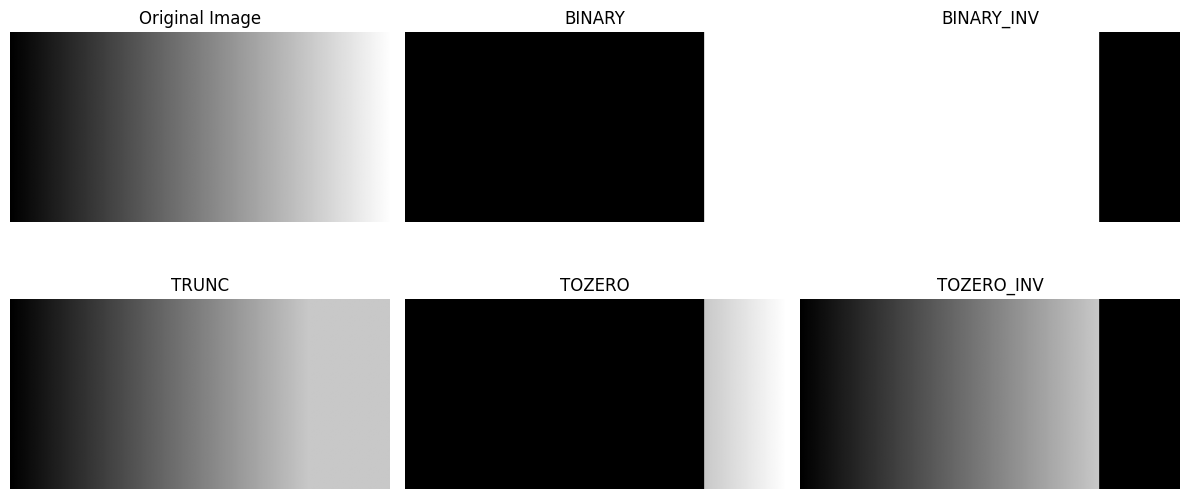

In [ ]:
original_image = np.zeros((200, 400), dtype=np.uint8)
for x in range(400):
    original_image[:, x] = int(x * 255 / 399)

thresh = 200
max_val = 255

binary = np.where(original_image > thresh, max_val, 0).astype(np.uint8)

binary_inv = np.where(original_image > thresh, 0, max_val).astype(np.uint8)

trunc = np.where(original_image > thresh, thresh, original_image).astype(np.uint8)

tozero = np.where(original_image > thresh, original_image, 0).astype(np.uint8)

tozero_inv = np.where(original_image > thresh, 0, original_image).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [original_image, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

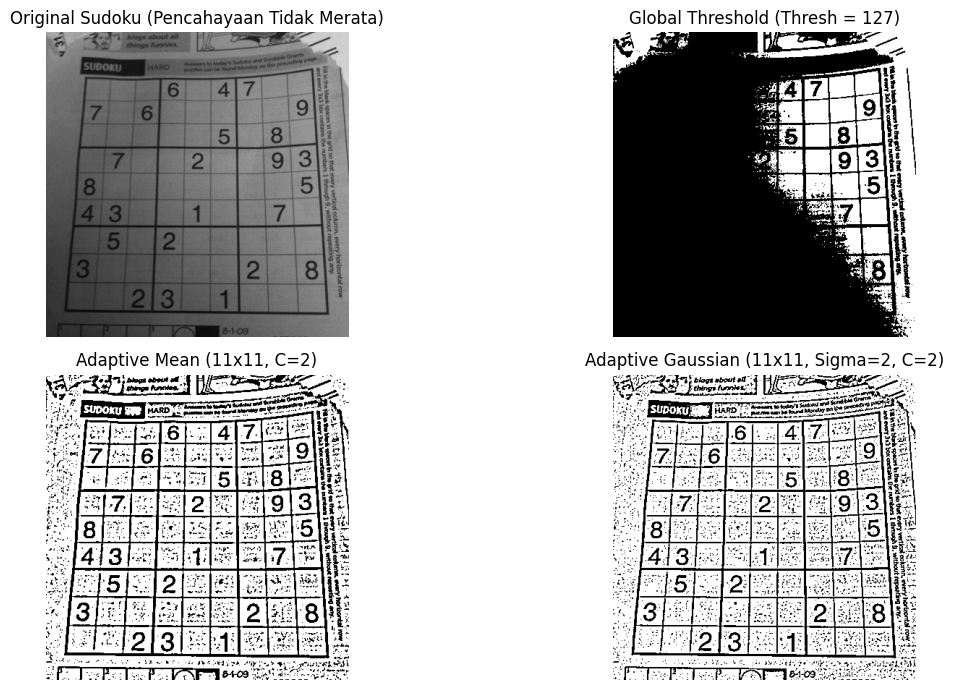

In [ ]:
path = '/content/drive/MyDrive/Images/sudoku-original.jpg'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError(f"Citra tidak ditemukan pada path: {path}. Pastikan Google Drive sudah di-mount dengan benar.")

h, w = img.shape
img_float = img.astype(np.float32)


global_thresh_val = 127
global_thresh = np.zeros_like(img)
global_thresh[img > global_thresh_val] = 255
global_thresh[img <= global_thresh_val] = 0


kernel_size = 11
pad = kernel_size // 2
C = 2

mean_thresh_img = np.zeros_like(img)

padded_img_mean = np.pad(img_float, pad, mode='edge')

for y in range(h):
    for x in range(w):
        window = padded_img_mean[y:y+kernel_size, x:x+kernel_size]
        local_mean = np.mean(window)

        if img_float[y, x] > (local_mean - C):
            mean_thresh_img[y, x] = 255
        else:
            mean_thresh_img[y, x] = 0


sigma = 2
gaussian_thresh_img = np.zeros_like(img)

ax = np.arange(-pad, pad + 1, dtype=np.float32)
kernel_1d = np.exp(-(ax**2) / (2 * (sigma**2)))
kernel_1d /= np.sum(kernel_1d)

gaussian_kernel_2d = np.outer(kernel_1d, kernel_1d)
gaussian_kernel_2d /= np.sum(gaussian_kernel_2d)

padded_img_gauss = np.pad(img_float, pad, mode='edge')

for y in range(h):
    for x in range(w):
        window = padded_img_gauss[y:y+kernel_size, x:x+kernel_size]
        local_gaussian_weighted_mean = np.sum(window * gaussian_kernel_2d)

        if img_float[y, x] > (local_gaussian_weighted_mean - C):
            gaussian_thresh_img[y, x] = 255
        else:
            gaussian_thresh_img[y, x] = 0


titles = ['Original Sudoku (Pencahayaan Tidak Merata)',
          'Global Threshold (Thresh = 127)',
          'Adaptive Mean (11x11, C=2)',
          'Adaptive Gaussian (11x11, Sigma=2, C=2)']
images = [img, global_thresh, mean_thresh_img, gaussian_thresh_img]

plt.figure(figsize=(14, 7))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()

Nilai Threshold Optimal (Otsu Manual): 122
Nilai Threshold OpenCV (Library): 122.0


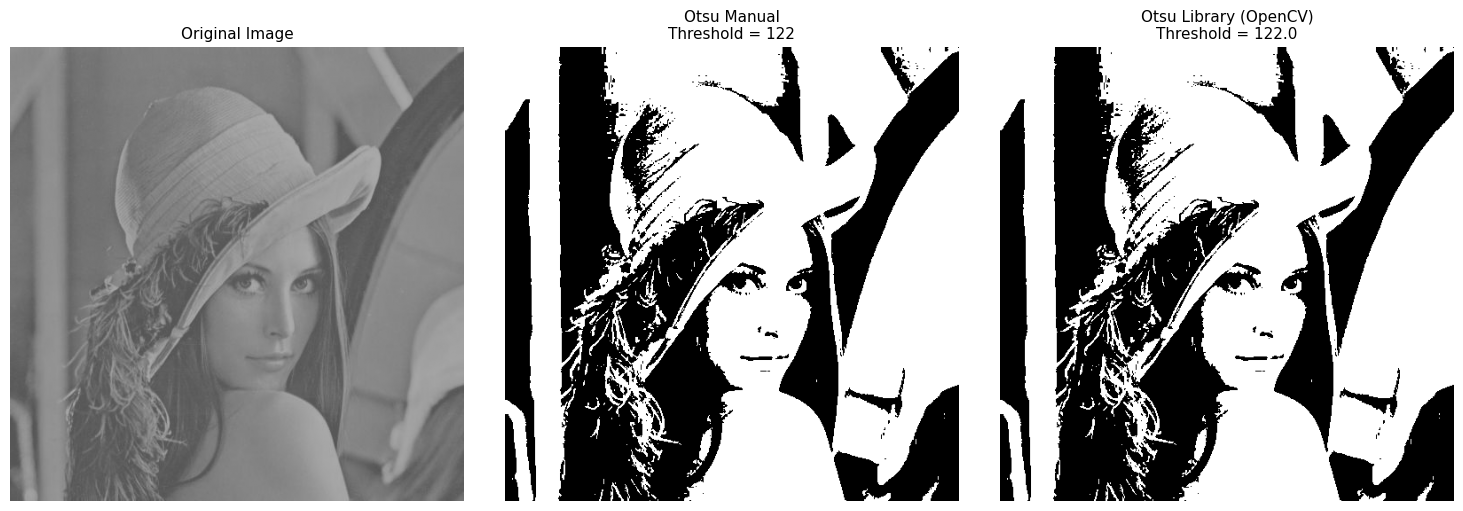

In [ ]:
path = '/content/drive/MyDrive/Images/lena_gs_lc.jpg'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError(f"Citra tidak ditemukan pada path: {path}. Pastikan Google Drive sudah di-mount dengan benar.")


def manual_otsu_threshold(image):
    # Menghitung histogram citra (256 tingkat keabuan dari 0 sampai 255)
    hist, _ = np.histogram(image.ravel(), bins=256, range=(0, 256))
    total_pixels = image.size

    current_max_variance = 0
    optimal_threshold = 0

    sum_total = np.dot(np.arange(256), hist)
    sum_background = 0
    weight_background = 0


    for t in range(256):
        weight_background += hist[t]
        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background
        if weight_foreground == 0:
            break

        sum_background += t * hist[t]


        mean_background = sum_background / weight_background
        mean_foreground = (sum_total - sum_background) / weight_foreground


        variance_between = weight_background * weight_foreground * (mean_background - mean_foreground) ** 2

        if variance_between > current_max_variance:
            current_max_variance = variance_between
            optimal_threshold = t

    manual_thresh_img = np.zeros_like(image)
    manual_thresh_img[image > optimal_threshold] = 255

    return optimal_threshold, manual_thresh_img

optimal_thresh, manual_result = manual_otsu_threshold(img)
print(f"Nilai Threshold Optimal (Otsu Manual): {optimal_thresh}")

library_thresh, library_result = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Nilai Threshold OpenCV (Library): {library_thresh}")

titles = [
    'Original Image',
    f'Otsu Manual\nThreshold = {optimal_thresh}',
    f'Otsu Library (OpenCV)\nThreshold = {library_thresh}'
]
images = [img, manual_result, library_result]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.show()

Nilai Threshold Optimal Otsu: 111


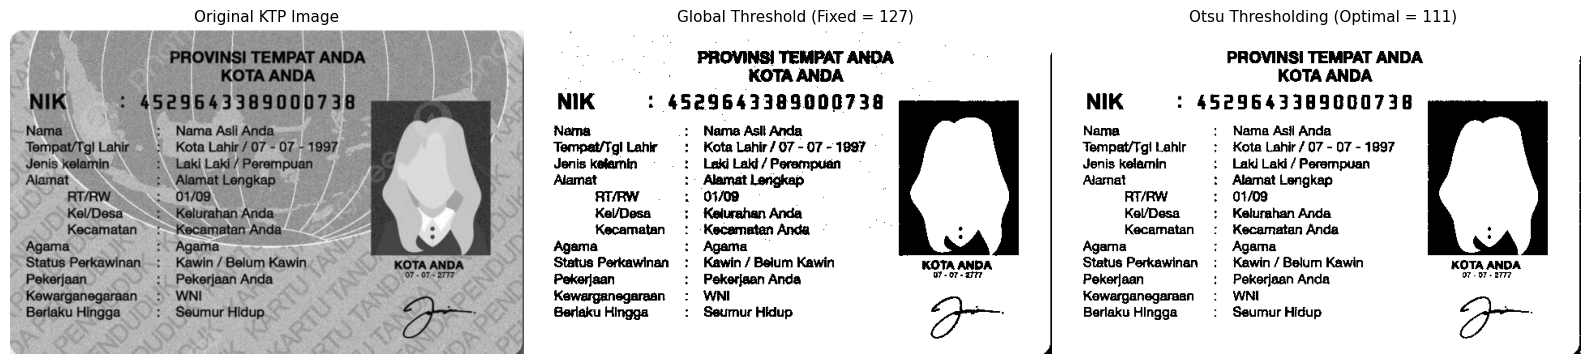

In [ ]:
path = '/content/drive/MyDrive/Images/ktp_fulani.jpg'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError(f"Citra KTP tidak ditemukan pada path: {path}. Pastikan file 'ktp.jpg' sudah diunggah ke Google Drive.")


global_thresh_value = 127
global_result = np.zeros_like(img)
global_result[img > global_thresh_value] = 255
global_result[img <= global_thresh_value] = 0


def manual_otsu_threshold(image):
    hist, _ = np.histogram(image.ravel(), bins=256, range=(0, 256))
    total_pixels = image.size

    current_max_variance = 0
    optimal_threshold = 0

    sum_total = np.dot(np.arange(256), hist)
    sum_background = 0
    weight_background = 0

    for t in range(256):
        weight_background += hist[t]
        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background
        if weight_foreground == 0:
            break

        sum_background += t * hist[t]

        mean_background = sum_background / weight_background
        mean_foreground = (sum_total - sum_background) / weight_foreground

        variance_between = weight_background * weight_foreground * (mean_background - mean_foreground) ** 2

        if variance_between > current_max_variance:
            current_max_variance = variance_between
            optimal_threshold = t

    otsu_result = np.zeros_like(image)
    otsu_result[image > optimal_threshold] = 255

    return optimal_threshold, otsu_result

optimal_thresh, otsu_result = manual_otsu_threshold(img)
print(f"Nilai Threshold Optimal Otsu: {optimal_thresh}")


titles = [
    'Original KTP Image',
    f'Global Threshold (Fixed = {global_thresh_value})',
    f'Otsu Thresholding (Optimal = {optimal_thresh})'
]
images = [img, global_result, otsu_result]

plt.figure(figsize=(16, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.show()

Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?

Hasil Binary Thresholding menjadi hitam semua karena nilai ambang batas (`thresh`) yang digunakan terlalu tinggi sehingga seluruh piksel citra berada di bawah atau sama dengan batas tersebut; dalam bentuk histogram, hal ini terjadi karena seluruh distribusi intensitas piksel terkonsentrasi di sebelah kiri garis `thresh`. Agar gambar Lena masih terlihat, nilai ambang batas harus diturunkan dan diletakkan di tengah-tengah rentang intensitas atau distribusi histogram citra tersebut (misalnya menggunakan nilai ambang optimal sekitar 80 hingga 110).

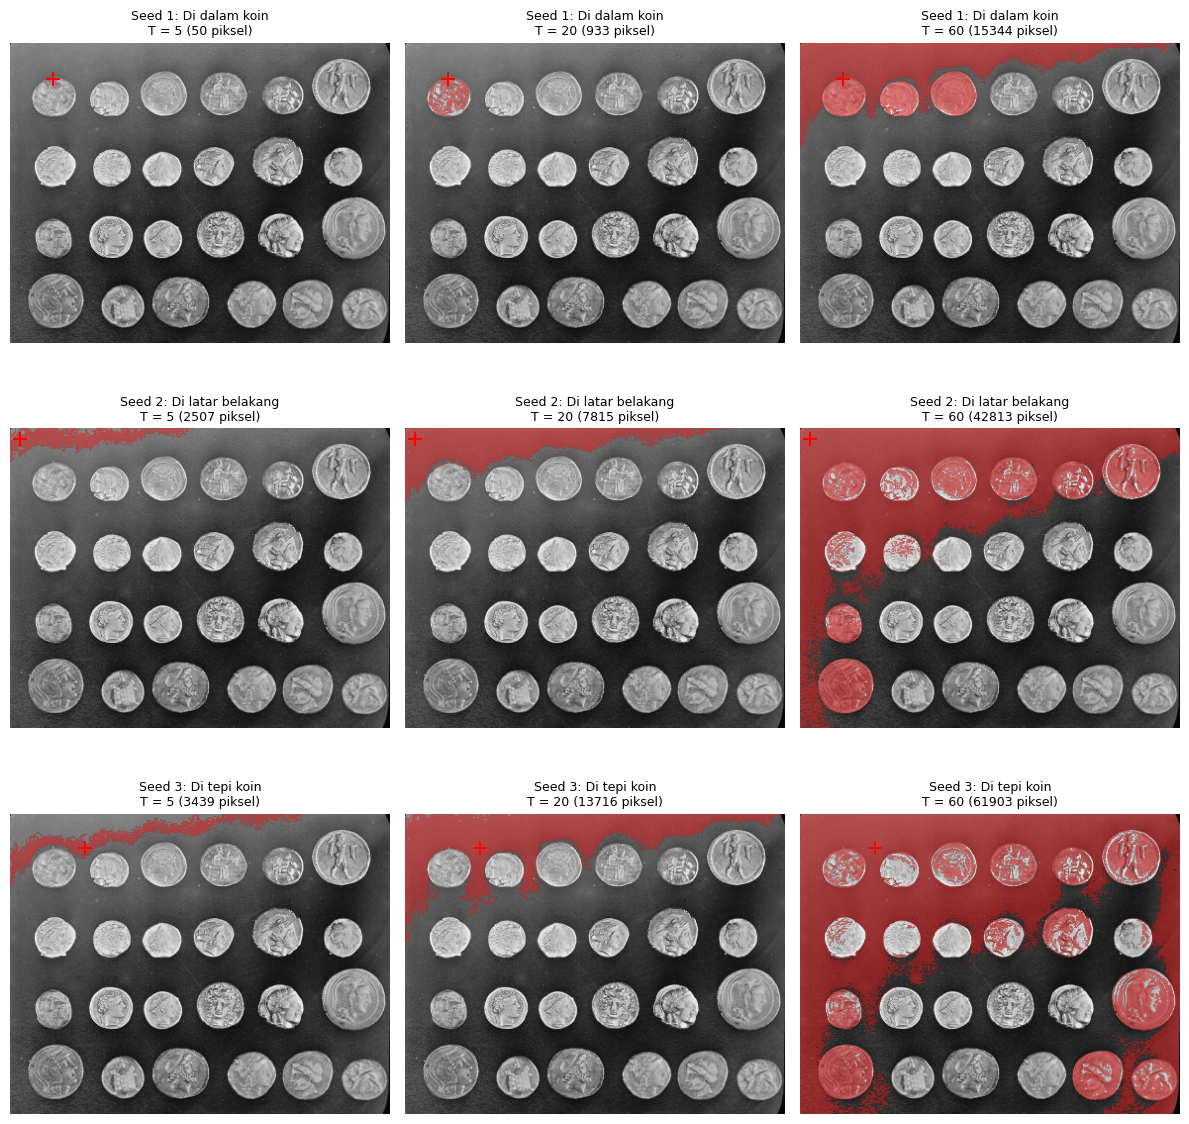

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.coins()
h, w = img.shape

seeds = [
    (36, 43),
    (10, 10),
    (34, 75)
]

seed_labels = ["Seed 1: Di dalam koin", "Seed 2: Di latar belakang", "Seed 3: Di tepi koin"]
T_values = [5, 20, 60]

def region_growing(image, seed, T):
    h, w = image.shape
    segmented = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)

    seed_val = float(image[seed])
    queue = [seed]
    visited[seed] = True

    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 (0, -1),           (0, 1),
                 (1, -1),  (1, 0),  (1, 1)]

    while queue:
        curr_y, curr_x = queue.pop(0)
        segmented[curr_y, curr_x] = True

        for dy, dx in neighbors:
            ny, nx = curr_y + dy, curr_x + dx
            if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx]:
                visited[ny, nx] = True
                if abs(float(image[ny, nx]) - seed_val) <= T:
                    queue.append((ny, nx))

    return segmented

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, seed in enumerate(seeds):
    for j, T in enumerate(T_values):
        seg_mask = region_growing(img, seed, T)
        pixel_count = np.sum(seg_mask)

        axes[i, j].imshow(img, cmap='gray')

        overlay = np.zeros((h, w, 4), dtype=np.float32)
        overlay[seg_mask] = [1, 0, 0, 0.4]
        axes[i, j].imshow(overlay)

        axes[i, j].scatter(seed[1], seed[0], color='red', marker='+', s=100)

        axes[i, j].set_title(f"{seed_labels[i]}\nT = {T} ({pixel_count} piksel)", fontsize=9)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

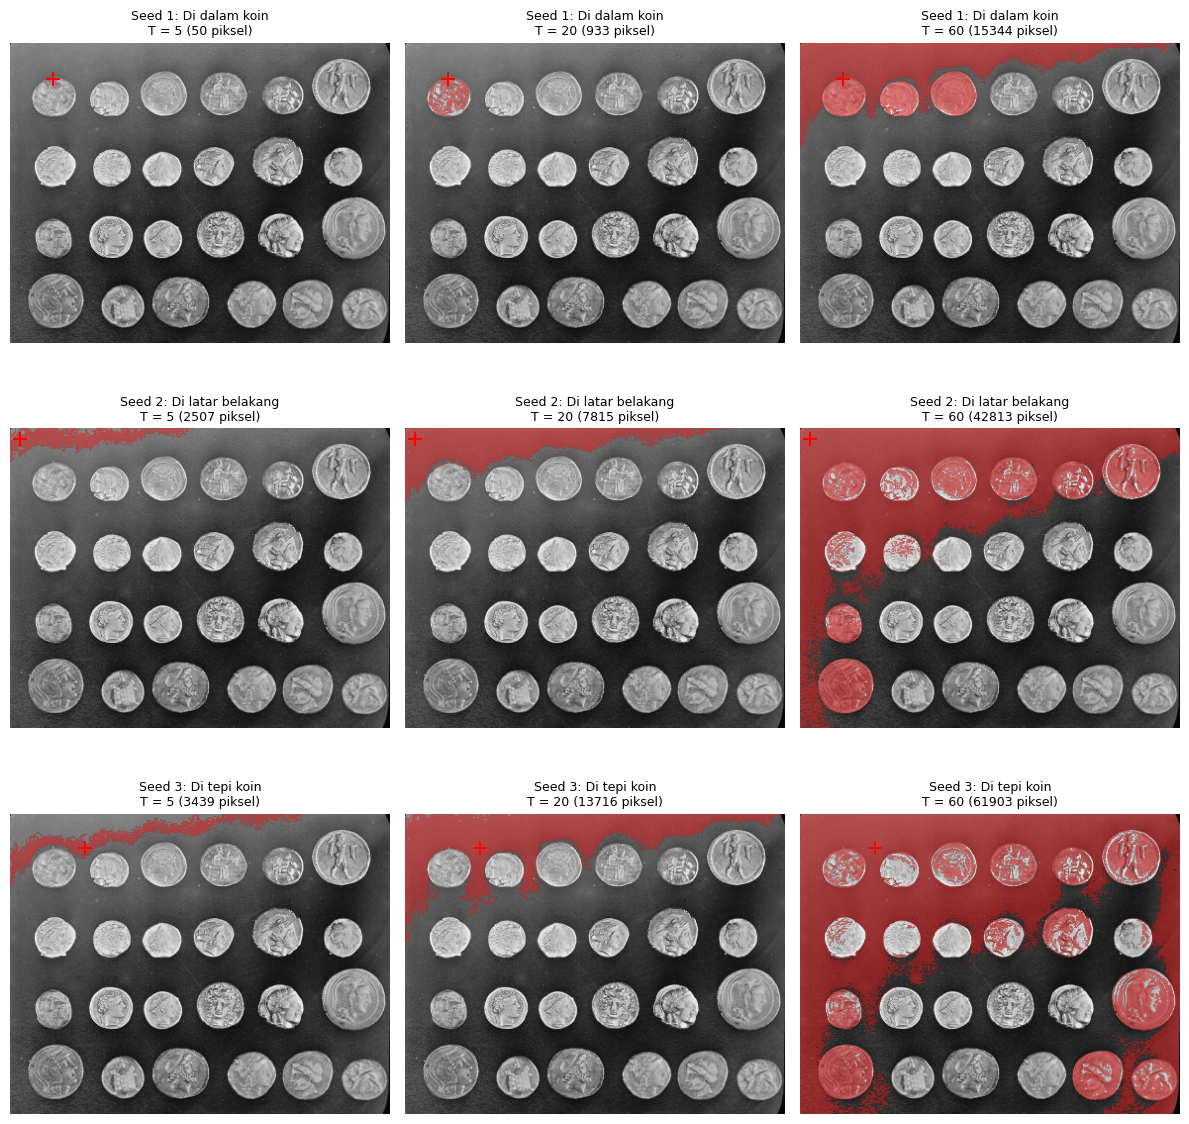

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.coins()
h, w = img.shape


seeds = [
    (36, 43),
    (10, 10),
    (34, 75)
]

seed_labels = ["Seed 1: Di dalam koin", "Seed 2: Di latar belakang", "Seed 3: Di tepi koin"]
T_values = [5, 20, 60]

def region_growing(image, seed, T):
    h, w = image.shape
    segmented = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)

    seed_val = float(image[seed])
    queue = [seed]
    visited[seed] = True

    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 (0, -1),           (0, 1),
                 (1, -1),  (1, 0),  (1, 1)]

    while queue:
        curr_y, curr_x = queue.pop(0)
        segmented[curr_y, curr_x] = True

        for dy, dx in neighbors:
            ny, nx = curr_y + dy, curr_x + dx
            if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx]:
                visited[ny, nx] = True
                if abs(float(image[ny, nx]) - seed_val) <= T:
                    queue.append((ny, nx))

    return segmented

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, seed in enumerate(seeds):
    for j, T in enumerate(T_values):
        seg_mask = region_growing(img, seed, T)
        pixel_count = np.sum(seg_mask)

        axes[i, j].imshow(img, cmap='gray')

        overlay = np.zeros((h, w, 4), dtype=np.float32)
        overlay[seg_mask] = [1, 0, 0, 0.4]
        axes[i, j].imshow(overlay)


        axes[i, j].scatter(seed[1], seed[0], color='red', marker='+', s=100)

        axes[i, j].set_title(f"{seed_labels[i]}\nT = {T} ({pixel_count} piksel)", fontsize=9)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

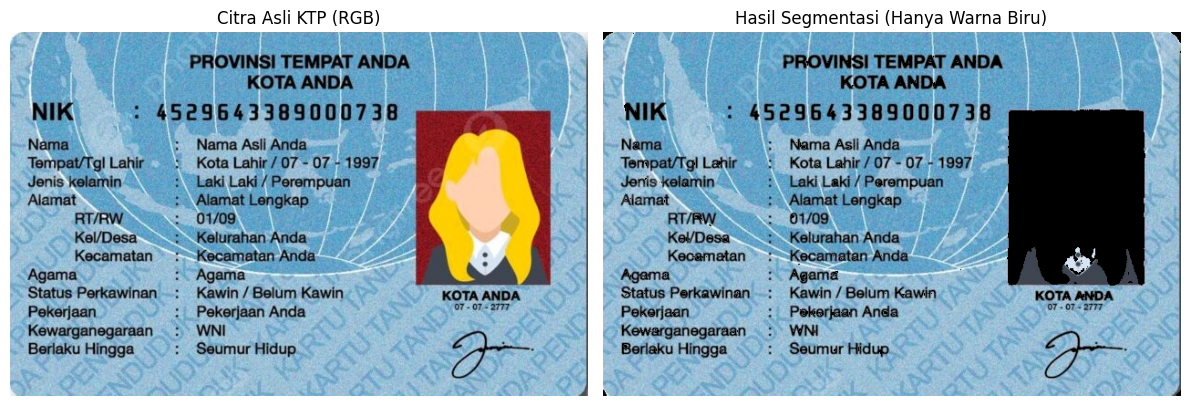

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

path = '/content/drive/MyDrive/Images/ktp_fulani.jpg'
img = cv2.imread(path)

if img is None:
    raise ValueError(f"Citra tidak ditemukan pada path: {path}. Pastikan path file dan Google Drive sudah benar.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H = img_hsv[:, :, 0]
S = img_hsv[:, :, 1]
V = img_hsv[:, :, 2]

kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

segmented_blue = np.zeros_like(img_rgb)
segmented_blue[kelompok_biru] = img_rgb[kelompok_biru]

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Citra Asli KTP (RGB)", fontsize=12)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_blue)
plt.title("Hasil Segmentasi (Hanya Warna Biru)", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()

## D2. Tugas Kelompok

In [3]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract opencv-python-headless pandas

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


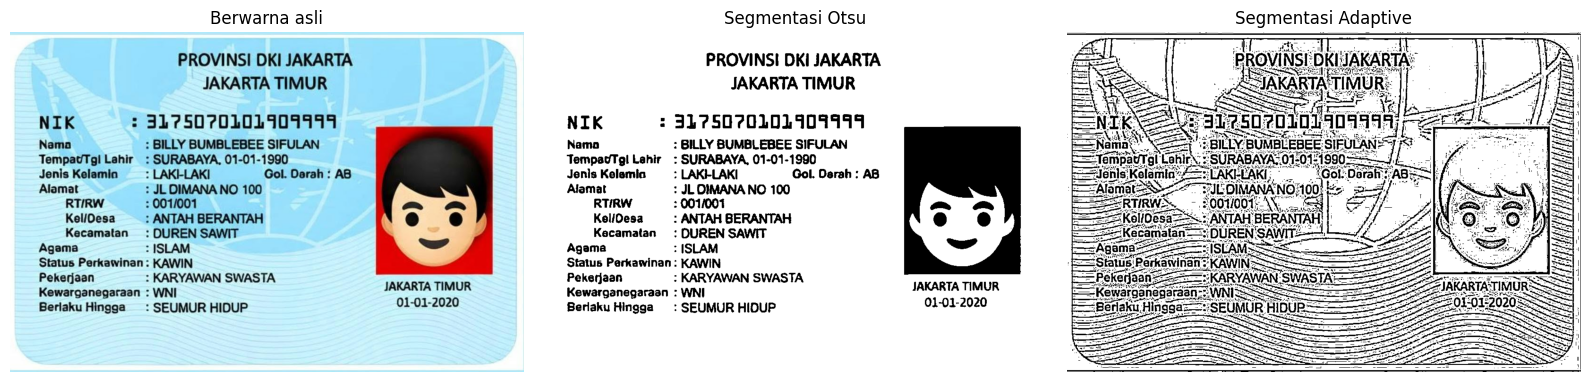

In [4]:
# 1. 3 Citra
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd

from google.colab import drive
from pytesseract import Output

filename = '/content/drive/MyDrive/D4 Teknik Informatika_Icha/ktp.jpeg'
img = cv2.imread(filename)

if img is None:
    raise FileNotFoundError("File KTP tidak ditemukan. Periksa nama dan lokasi file.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, otsu = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

adaptive = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

images = {
    'Berwarna asli': cv2.cvtColor(img, cv2.COLOR_BGR2RGB),
    'Segmentasi Otsu': otsu,
    'Segmentasi Adaptive': adaptive
}

plt.figure(figsize=(16, 6))
for i, (name, image) in enumerate(images.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(image, cmap='gray' if image.ndim == 2 else None)
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# 2
config = '--psm 6'
ocr_results = {}
boxed_images = {}
confidence_summary = {}

for name, image in images.items():
    if image.ndim == 3:
        ocr_input = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    else:
        ocr_input = image

    text_result = pytesseract.image_to_string(
        ocr_input,
        lang='ind',
        config=config
    )
    data = pytesseract.image_to_data(
        ocr_input,
        lang='ind',
        config=config,
        output_type=Output.DICT
    )

    if ocr_input.ndim == 2:
        boxed = cv2.cvtColor(
            ocr_input, cv2.COLOR_GRAY2RGB
        )
    else:
        boxed = cv2.cvtColor(
            ocr_input, cv2.COLOR_BGR2RGB
        )

    valid_conf = []

    for i in range(len(data['text'])):
        word = data['text'][i].strip()

        try:
            conf = float(data['conf'][i])
        except ValueError:
            continue

        if word and conf >= 60:
            x = data['left'][i]
            y = data['top'][i]
            w = data['width'][i]
            h = data['height'][i]

            cv2.rectangle(
                boxed,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            valid_conf.append(conf)

    ocr_results[name] = text_result
    boxed_images[name] = boxed

    confidence_summary[name] = (
        np.mean(valid_conf) if valid_conf else 0
    )

    print(f'\n{"=" * 50}')
    print(name)
    print("=" * 50)
    print(text_result)


Berwarna asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?5070101404441
Nama : BILLY BUMBLEBEE SIFULAN
TempatTgi Lahir : SURABAYA. 01-01-1990
Jenis Kelamia 1 LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

Kel/desa : ANTAH BERANTAH h

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan 1 KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA Bra
Berlaku Hingga — : SEUMUR HIDUP 01-01-202


Segmentasi Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?5070101909944
Nama 1 BILLY BUMBLEBEE SIFULAN
TempavTgi Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Derah : AB
Alamat ? JL DIMANA NO 100

RTIRW : 0011001

Kol/Desa 1 ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga : SEUMUR HIDUP 01-01-2020


Segmentasi Adaptive
se) i Te Ai —e — sdt 1 7 PK
na #ROVINSI DKIJAKARTA: dh IA
AI | gE JAKARTA TIMUR. | ne NS
NIK SA Aheal (DO L ——— LH
AA asn at, Ko
—-Nama "NE

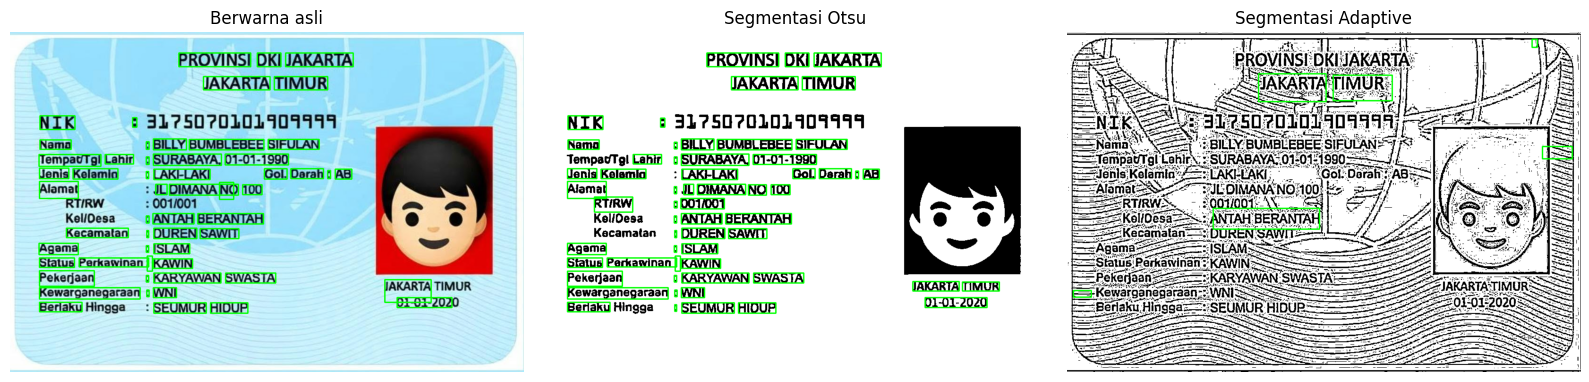

In [6]:
# 3
plt.figure(figsize=(16, 7))

for i, (name, boxed) in enumerate(boxed_images.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(boxed)
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
# 4
reference = [
    'PROVINSI',
    'JAKARTA',
    'TIMUR',
    'NIK',
    'Nama',
    'Tempat/Tgl',
    'Lahir',
    'Jenis',
    'Kelamin',
    'Agama'
]

def normalize(text):
    return ' '.join(str(text).strip().lower().split())

ocr_lines = {}

for name, text_result in ocr_results.items():
    ocr_lines[name] = [
        normalize(line)
        for line in text_result.splitlines()
        if line.strip()
    ]

table_rows = []

for item in reference:
    row = {'Teks sebenarnya': item}

    for name, text_result in ocr_results.items():
        normalized_result = normalize(text_result)

        import re
        pattern = r'(?<!\w)' + re.escape(
            normalize(item)
        ) + r'(?!\w)'

        match = bool(re.search(pattern, normalized_result))

        row[name] = 'Cocok' if match else 'Tidak cocok'

    table_rows.append(row)

comparison = pd.DataFrame(table_rows)
display(comparison)


,Teks sebenarnya,Berwarna asli,Segmentasi Otsu,Segmentasi Adaptive
0,PROVINSI,Cocok,Cocok,Tidak cocok
1,JAKARTA,Cocok,Cocok,Cocok
2,TIMUR,Cocok,Cocok,Cocok
3,NIK,Cocok,Cocok,Cocok
4,Nama,Cocok,Cocok,Cocok
5,Tempat/Tgl,Tidak cocok,Tidak cocok,Cocok
6,Lahir,Cocok,Cocok,Cocok
7,Jenis,Cocok,Cocok,Cocok
8,Kelamin,Tidak cocok,Cocok,Tidak cocok
9,Agama,Cocok,Cocok,Tidak cocok


In [8]:
# 5.
summary_rows = []

for name in images.keys():

    total_correct = sum(
        1 for item in reference
        if comparison.loc[
            comparison['Teks sebenarnya'] == item, name
        ].iloc[0] == 'Cocok'
    )

    percentage = total_correct / len(reference) * 100

    summary_rows.append({
        'Citra masukan OCR': name,
        'Item terbaca tepat': f'{total_correct}/{len(reference)}',
        'Kecocokan (%)': percentage,
        'Rata-rata confidence': confidence_summary[name]
    })

summary = pd.DataFrame(summary_rows)

display(
    summary.style.format({
        'Kecocokan (%)': '{:.2f}%',
        'Rata-rata confidence': '{:.2f}'
    })
)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,8/10,80.00%,90.64
1,Segmentasi Otsu,9/10,90.00%,90.22
2,Segmentasi Adaptive,7/10,70.00%,75.50


### Pertanyaan Analisis

### Jawaban Pertanyaan Analisis

Based on the experiment and the comparison dataframes generated above, here are the answers to the analysis questions:

#### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
**Citra masukan yang menghasilkan pembacaan paling tepat adalah Segmentasi Otsu.**
*   **Bukti dari tabel ringkasan (`summary`):**
    *   **Segmentasi Otsu** memperoleh **Item terbaca tepat: 9/10** dengan **Kecocokan: 90.00%**.
    *   **Berwarna asli** memperoleh **Item terbaca tepat: 8/10** dengan **Kecocokan: 80.00%**.
    *   **Segmentasi Adaptive** memperoleh **Item terbaca tepat: 7/10** dengan **Kecocokan: 70.00%**.

#### 2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
Beberapa kesalahan pembacaan (misread) yang terjadi pada hasil OCR:
*   **Kesalahan Angka NIK (Angka Salah):** Pada citra *Berwarna asli*, angka NIK terbaca sebagai `31?5070101404441` dan pada *Segmentasi Otsu* terbaca sebagai `31?5070101909944`, padahal angka asli pada KTP adalah `3175070101909999`.
*   **Kesalahan Huruf/Teks pada Field Name (Huruf Tertukar/Teks Rusak):**
    *   Kata `Tempat/Tgl` terbaca sebagai `TempatTgi` (huruf l berubah menjadi i) atau `TempavTgi` pada segmentasi Otsu.
    *   Kata `Jenis Kelamin` terbaca sebagai `Jenis Kelamia 1` pada citra berwarna asli.

#### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
**Tidak selalu.**
*   Meskipun **Segmentasi Otsu** berhasil meningkatkan ketepatan OCR dari 80.00% (citra asli) menjadi 90.00%, **Segmentasi Adaptive** justru menurunkan ketepatannya menjadi 70.00%.
*   Hal ini menunjukkan bahwa kecocokan metode segmentasi sangat bergantung pada karakteristik citra. Segmentasi yang terlalu agresif atau sensitif (seperti Adaptive Thresholding pada citra dengan latar belakang bertekstur/pola air) dapat memunculkan banyak *noise* atau garis latar belakang (misalnya pola peta dunia pada KTP) yang ikut terbinarisasi, sehingga malah mengganggu pembacaan karakter oleh mesin OCR.

#### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
*   **Warna latar belakang** yang kontrasnya rendah dengan teks dapat mempersulit OCR dalam memisahkan batas karakter (karakter menjadi samar).
*   **Pola latar belakang** (seperti pola garis-garis halus, peta, atau hologram pada KTP) sering kali dianggap sebagai bagian dari karakter teks oleh algoritma OCR ketika dilakukan binarisasi. Pada hasil *Segmentasi Adaptive*, terlihat pola latar belakang KTP ikut terdeteksi sebagai garis hitam tebal yang memotong atau menempel pada huruf asli, sehingga teks menjadi tidak terbaca (*corrupted*).

#### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
**Tidak selalu.**
*   Pada hasil percobaan ini, **Berwarna asli** memiliki **Rata-rata confidence tertinggi (90.64)**, namun tingkat kecocokan teksnya (**80.00%**) lebih rendah dibandingkan dengan **Segmentasi Otsu** yang memiliki **Kecocokan tertinggi (90.00%)** tetapi dengan rata-rata confidence sedikit di bawahnya, yaitu **90.22**.
*   Hal ini terjadi karena nilai *confidence* yang dilaporkan oleh Tesseract hanya menunjukkan tingkat keyakinan mesin terhadap karakter yang dideksripsinya, bukan jaminan ketepatan semantik (apakah kata tersebut benar-benar cocok dengan kata referensi asli).